# Hugging Face models: local Chronos-Bolt comparison

We tested Amazon's [Chronos-Bolt Tiny and Small](https://huggingface.co/amazon/chronos-bolt-small), pretrained time-series models that forecast without fitting to this dataset. Both run locally on CPU in a separate Python 3.12 environment. The project data are not sent to a hosted inference service.

Each model sees 168, 504, or 1536 past generation values and predicts the next 48 hours. We use its median forecast, not a claimed conditional mean. Two fixed 50/50 blends combine the 504-hour models with SARIMA. No weather inputs or fine-tuning are used. Model revisions and package versions are recorded for reproduction.

## Comparable validation
The same six calibration blocks, eleven selection blocks, and one previously examined audit as the expanded search are used. Previous candidate predictions are reused, avoiding refits and ensuring identical comparisons. Weather stress affects earlier weather models; Chronos and its SARIMA blends do not change across those scenarios. Repeated stress seeds do not create independent historical windows.

The lowest pooled stress-scenario RMSE selects the overall candidate, including all prior models and seasonal naive. A separate best-HF forecast is saved even if the pretrained models lose. The audit does not select the model. Reusing validation across searches introduces selection optimism; no future hidden targets are available.

Nominal 95% intervals use historical rolling errors, separately for day one and day two. **Native Bolt quantiles are not labeled as 95% intervals.** Calibration is fixed on the six earlier blocks during validation, then refreshed with all completed historical blocks for the actual future forecast. Coverage is empirical, not guaranteed.

Only provided data are used as local inputs; pretrained weights are external model artifacts. Pretraining overlap with the disguised series cannot be independently verified, and no attempt was made to identify its original source.

To rerun, follow the Hugging Face commands in `README.md`. This notebook itself uses the original `Time Series (.venv)` kernel and reads saved results.


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
out=Path("results_hf")
report=json.loads((out/"run_summary.json").read_text())
summary=pd.read_csv(out/"model_comparison.csv")
windows=pd.read_csv(out/"window_comparison.csv",parse_dates=["start","end"])
consistency=pd.read_csv(out/"window_consistency.csv")
winner=report["selected_model"]; hf_winner=report["best_hf_candidate"]
focus=list(dict.fromkeys(report["hf_candidates"]+["seasonal_naive","SARIMA_21d","blend_SARIMA50_hour50"]))
SCENARIO="weather_stress"
selection=summary[(summary.phase=="selection")&(summary.scenario==SCENARIO)]
print("Overall winner:",winner,"\nBest HF candidate:",hf_winner)
display(selection[selection.model.isin(focus)].set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))


Overall winner: blend_SARIMA50_hour50 
Best HF candidate: blend_SARIMA50_bolt_small504_50


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
blend_SARIMA50_hour50,277.105,0.871,355.026,1422.269,0.888
blend_SARIMA50_bolt_small504_50,298.693,0.939,237.719,1424.325,0.917
blend_SARIMA50_bolt_tiny504_50,303.341,0.953,245.756,1426.778,0.915
chronos_bolt_small_504h,307.954,0.968,222.604,1637.045,0.896
chronos_bolt_tiny_1536h,313.299,0.985,264.217,1621.038,0.883
chronos_bolt_tiny_504h,315.019,0.990,239.361,1585.746,0.896
chronos_bolt_small_1536h,317.234,0.997,239.489,1760.103,0.905
seasonal_naive,318.144,1.000,392.611,2258.119,0.771
SARIMA_21d,320.563,1.008,257.281,1466.273,0.928


## Window-by-window consistency
Below 1 beats seasonal naive. The final column is the previously seen audit; win counts use selection windows only.

label,Oct 03,Oct 05,Oct 07,Oct 09,Oct 11,Oct 13,Oct 15,Oct 17,Oct 19,Oct 21,Oct 23,Oct 25 [audit]
model,,,,,,,,,,,,
blend_SARIMA50_hour50,0.89,1.02,0.92,1.08,0.58,0.99,0.75,0.65,0.70,1.00,1.14,1.35
blend_SARIMA50_bolt_small504_50,0.87,1.22,0.79,0.89,0.69,1.07,0.88,0.66,0.83,1.33,1.62,1.20
blend_SARIMA50_bolt_tiny504_50,0.87,1.23,0.78,0.94,0.69,1.07,0.92,0.67,0.90,1.35,1.55,1.12
chronos_bolt_small_504h,0.86,1.21,0.76,0.72,0.78,1.12,0.88,0.55,0.79,1.48,2.35,1.93
chronos_bolt_tiny_1536h,0.81,1.27,0.81,0.70,0.63,1.05,0.94,0.66,0.95,1.50,2.16,1.46
chronos_bolt_tiny_504h,0.86,1.23,0.79,0.83,0.70,1.10,0.98,0.54,1.00,1.49,2.20,1.62
chronos_bolt_small_1536h,0.82,1.39,0.79,0.57,0.68,1.02,0.75,0.59,0.78,1.51,2.70,2.58
seasonal_naive,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
SARIMA_21d,0.90,1.26,0.97,1.10,0.83,1.08,0.94,0.85,0.98,1.24,0.97,0.96


,windows,wins,mean_RMSE,median_RMSE_ratio,best_RMSE_ratio,worst_RMSE_ratio,mean_rank,win_rate
model,,,,,,,,
blend_SARIMA50_hour50,11,8,267.492,0.922,0.582,1.137,9.273,0.727
chronos_bolt_small_1536h,11,7,297.679,0.794,0.574,2.702,11.909,0.636
blend_SARIMA50_bolt_small504_50,11,7,290.607,0.878,0.657,1.624,13.909,0.636
chronos_bolt_small_504h,11,7,297.199,0.864,0.554,2.353,14.000,0.636
chronos_bolt_tiny_1536h,11,7,301.701,0.939,0.631,2.157,14.364,0.636
blend_SARIMA50_bolt_tiny504_50,11,7,295.163,0.921,0.670,1.551,14.727,0.636
chronos_bolt_tiny_504h,11,7,304.998,0.975,0.542,2.197,15.000,0.636
SARIMA_21d,11,7,309.648,0.972,0.833,1.257,19.000,0.636
chronos_bolt_small_168h,11,6,324.986,0.995,0.763,2.145,18.091,0.545


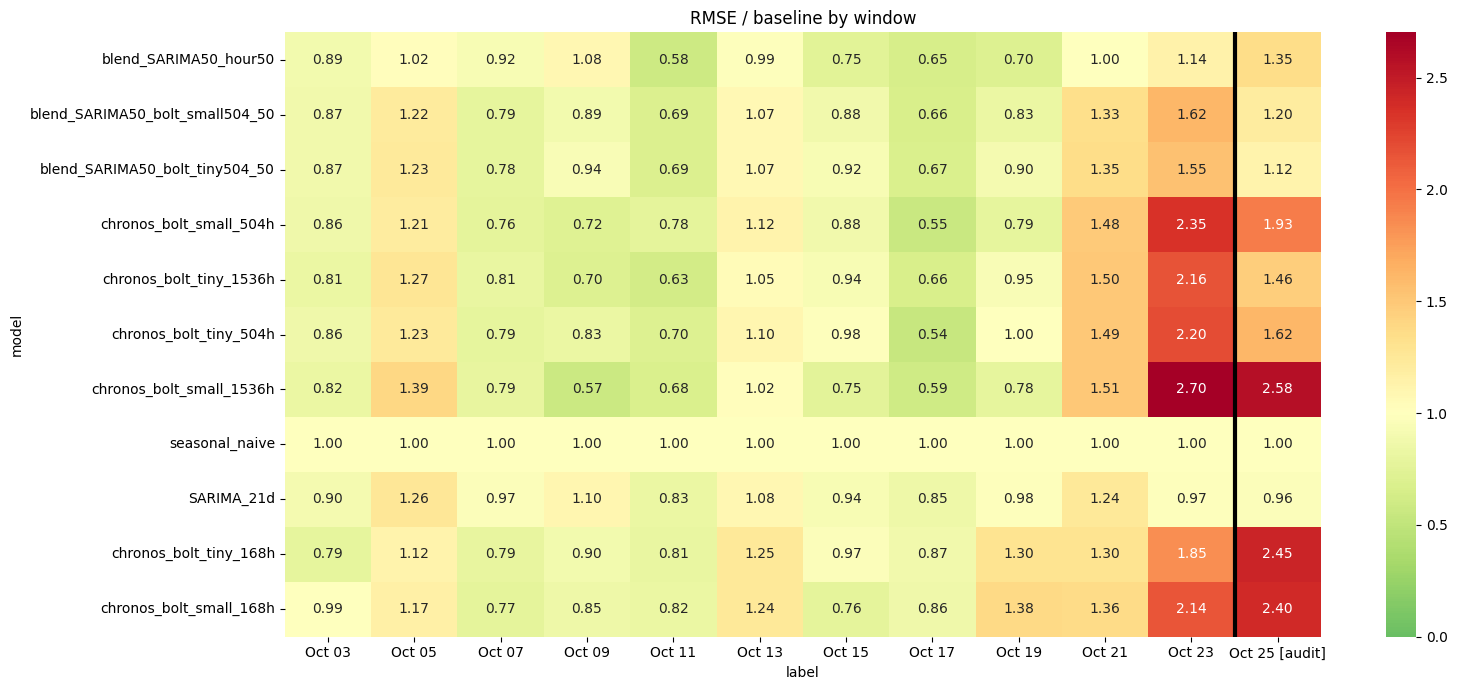

In [2]:
w=windows[(windows.scenario==SCENARIO)&windows.model.isin(focus)].copy()
w["label"]=w.start.dt.strftime("%b %d")+np.where(w.phase.eq("selection"),""," [audit]")
labels=w.sort_values("start").label.drop_duplicates().tolist()
order=selection[selection.model.isin(focus)].sort_values("RMSE").model.tolist()
ratios=w.pivot(index="model",columns="label",values="RMSE_ratio").reindex(index=order,columns=labels)
display(ratios.round(2))
display(consistency[(consistency.scenario==SCENARIO)&consistency.model.isin(focus)].set_index("model").drop(columns="scenario").round(3))
fig,ax=plt.subplots(figsize=(16,7))
sns.heatmap(ratios,annot=True,fmt=".2f",cmap="RdYlGn_r",center=1,vmin=0,vmax=max(2,float(ratios.max().max())),ax=ax)
ax.axvline(11,color="black",lw=3);ax.set_title("RMSE / baseline by window")
plt.tight_layout();fig.savefig(out/"hf_window_comparison.png",dpi=150,bbox_inches="tight");plt.show()


## Latest audit and day-two performance
The audit was seen before and is not an untouched test. Historical day-two scores are relevant to the final private leaderboard but do not reveal hidden scores.

In [3]:
audit=summary[(summary.phase=="last_window_audit")&(summary.scenario==SCENARIO)&summary.model.isin(focus)]
print("Latest audit")
display(audit.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
day2=pd.read_csv(out/"day_two_comparison.csv")
print("Day two across eleven selection windows")
display(day2[(day2.scenario==SCENARIO)&day2.model.isin(focus)].sort_values("RMSE").set_index("model").drop(columns="scenario").round(3))


Latest audit


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
SARIMA_21d,116.108,0.964,38.789,904.063,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
blend_SARIMA50_bolt_tiny504_50,134.807,1.120,37.892,789.503,1.000
blend_SARIMA50_bolt_small504_50,144.979,1.204,41.556,799.292,1.000
blend_SARIMA50_hour50,162.473,1.349,50.306,716.054,0.993
chronos_bolt_tiny_1536h,176.137,1.463,45.549,726.172,1.000
chronos_bolt_tiny_504h,195.423,1.623,45.415,761.617,1.000
chronos_bolt_small_504h,232.758,1.933,54.972,796.089,0.958
chronos_bolt_small_168h,288.703,2.398,75.020,1105.038,0.896


Day two across eleven selection windows


,RMSE,MAPE,Winkler,coverage,mean_width
model,,,,,
blend_SARIMA50_hour50,290.912,236.189,1593.711,0.851,763.895
blend_SARIMA50_bolt_small504_50,331.640,241.991,1594.356,0.871,892.633
blend_SARIMA50_bolt_tiny504_50,334.555,247.259,1552.289,0.871,906.372
chronos_bolt_small_504h,342.063,234.178,2016.139,0.852,827.930
chronos_bolt_tiny_1536h,344.353,262.848,1933.904,0.833,830.531
chronos_bolt_tiny_504h,344.543,242.263,1897.407,0.845,843.107
chronos_bolt_small_1536h,348.127,248.220,2041.527,0.883,860.985
seasonal_naive,349.503,294.002,2367.151,0.811,764.244
SARIMA_21d,356.215,255.318,1529.783,0.902,1065.476


## Future forecast
The best HF candidate and overall selected forecast may be different. Existing forecasts remain in their original folders.

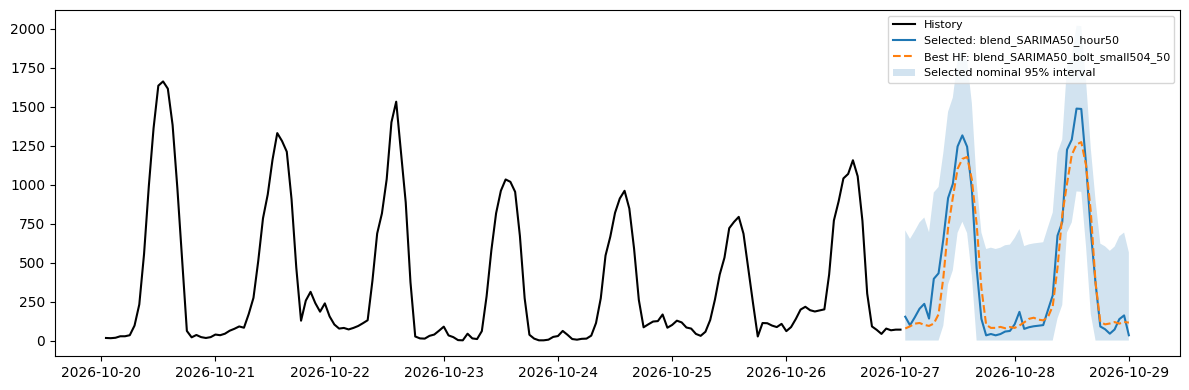

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,152.750033,0.0,706.553598
1,2026-10-27 02:00:00,97.927367,0.0,651.730931
2,2026-10-27 03:00:00,148.769080,0.0,702.572644
3,2026-10-27 04:00:00,203.942277,0.0,757.745841
4,2026-10-27 05:00:00,235.283437,0.0,789.087002


In [4]:
data=pd.read_csv("train.csv",parse_dates=["ds"])
sub=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
hf=pd.read_csv(out/"best_hf_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],label="History",color="black")
ax.plot(sub.ds,sub.forecast,label=f"Selected: {winner}")
if winner!=hf_winner:ax.plot(hf.ds,hf.forecast,label=f"Best HF: {hf_winner}",linestyle="--")
ax.fill_between(sub.ds,sub.lower_95,sub.upper_95,alpha=.2,label="Selected nominal 95% interval")
ax.legend(fontsize=8);plt.tight_layout();fig.savefig(out/"hf_forecast.png",dpi=150,bbox_inches="tight");plt.show()
display(sub.head())


## Save selected forecast for Moodle
Enter your surname to save the overall selected candidate. This does not upload anything.

In [5]:
SURNAME=""
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME to create the required Moodle filename.")


Set SURNAME to create the required Moodle filename.
